In [1]:
from notebook_setup import add_project_path_to_notebook

add_project_path_to_notebook()

from edmri.paths import CONFIG_PATH, PROJECT_ROOT, RESULTS_PATH, EXAMPLE_DATA_PATH, CONFIG_PATH, EXAMPLE_OPTIMISE_RESULTS_PATH, EXAMPLE_APPLY_RESULTS_PATH

print("Found project root and path to simulated data at the following locations")
print(f"Project root: {PROJECT_ROOT}")
print(f"Results path: {RESULTS_PATH}")
print(f"Example data path: {EXAMPLE_DATA_PATH}")
print(f"Configuration files path: {CONFIG_PATH}")
print(f"Example optimisation results path: {EXAMPLE_OPTIMISE_RESULTS_PATH}")
print(f"Example application results path: {EXAMPLE_APPLY_RESULTS_PATH}")


Found project root and path to simulated data at the following locations
Project root: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI
Results path: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/results
Example data path: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/examples/data
Configuration files path: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/edmri/conf
Example optimisation results path: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/results/optimisation/examples
Example application results path: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/results/application/examples


In [2]:
MODEL = "T1INV"

In [3]:
#simulate data

import sys
import numpy as np

RUN_SIMULATION = True

if RUN_SIMULATION:
    !{sys.executable} "{PROJECT_ROOT}/examples/generate_simulation_data.py" \
        "--model" {MODEL} \
        "--n-samples" 10000 \
    #!{sys.executable} "{PROJECT_ROOT}/examples/generate_simulation_data.py"


#
super_protocol_path = EXAMPLE_DATA_PATH / MODEL / "superdesign_protocol.txt"
super_signals_path = EXAMPLE_DATA_PATH / MODEL / "superdesign_signals.npy"
super_targets_path = EXAMPLE_DATA_PATH / MODEL / "superdesign_targets.npy"

super_protocol = np.atleast_2d(np.loadtxt(super_protocol_path))
super_signals = np.load(super_signals_path)
super_targets = np.load(super_targets_path)



Simulated MRI data generation complete.
Model:              T1INV
Number of voxels:   10000
Protocol length:    192
SNR range:          10 - 50
Signals dim:        (10000, 192)
Targets dim:        (10000, 1)
Protocol dim:       (192,)
Protocol:            Default superdesign for T1INV model.
Saved to:           /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/examples/data/T1INV
  - superdesign_signals.npy: simulated MRI signals
  - superdesign_targets.npy: corresponding ground-truth model parameters



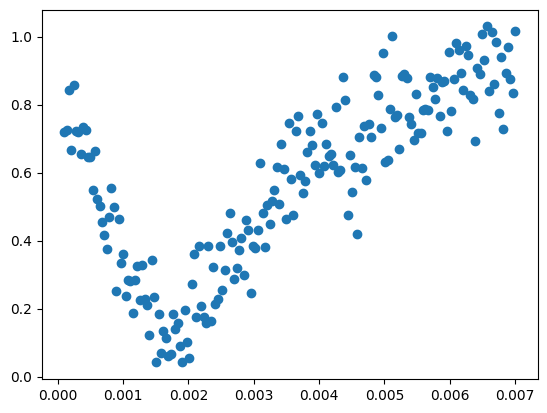

In [4]:
import matplotlib.pyplot as plt

from edmri.models.sandi import _calculate_b

if MODEL == "SANDI":
    b_super = _calculate_b(super_protocol[:, 0] * 1e-3, super_protocol[:, 1] * 1e-3, super_protocol[:, 2] * 1e-3)
    Delta = super_protocol[:, 1] 

    plt.scatter(
        b_super,
        super_signals[0, :],
        c=Delta,
        cmap="viridis",
        s=40,
    )

        
    plt.ylabel("Signal")
    plt.xlabel("b-value (s/mm²)")
    plt.colorbar(label="Δ (ms)")

else:
    plt.plot(super_protocol[0,:] * 1e-3, super_signals[0, :], "o")






In [5]:
#run tadred
RUN_OPTIMISE = True

if RUN_OPTIMISE:
    !edmri-optimise \
        --example {MODEL} \
        --config "{CONFIG_PATH}/optimise_default.yaml" \
        "data.input={super_signals_path}" \
        "data.target={super_targets_path}" \
        "data.superdesign={super_protocol_path}" \
        --force

    
    
    

INFO:tadred.data_processing:concatenated ['train'] on voxel dim
INFO:tadred.data_processing:Target data found
INFO:tadred.data_processing:concatenated ['val'] on voxel dim
INFO:tadred.data_processing:Target data found
INFO:tadred.data_processing:concatenated ['test'] on voxel dim
INFO:tadred.data_processing:Target data found
INFO:tadred.tadred_main:data_norm:
  data_fil: null
  data_train_subjs:
  - train
  data_val_subjs:
  - val
  data_test_subjs:
  - test
  data_normalization: original-measurement
output:
  out_base: /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/results/optimisation/examples/T1INV
  proj_name: tadred_results
  run_name: tadred_output_
network:
  num_units_score:
  - 1000
  - 1000
  num_units_task:
  - 1000
  - 1000
  score_activation: doublesigmoid
tadred_train_eval:
  feature_set_sizes_Ci:
  - 192
  - 156
  - 120
  - 84
  - 48
  feature_set_sizes_evaluated:
  - 192
  - 156
  - 120
  - 84
  - 48
  epochs: 1000
  epochs_fix_sigma: 25
  epochs_decay_sigma: 10
  epochs

In [6]:
task_network_path = EXAMPLE_OPTIMISE_RESULTS_PATH / MODEL / "tadred_results" / "trained_task_network.pt"
optimised_protocol_path = EXAMPLE_OPTIMISE_RESULTS_PATH / MODEL / "tadred_results" / "optimised_protocol.txt"
optimised_indices_path = EXAMPLE_OPTIMISE_RESULTS_PATH / MODEL / "tadred_results" / "optimised_indices.txt"

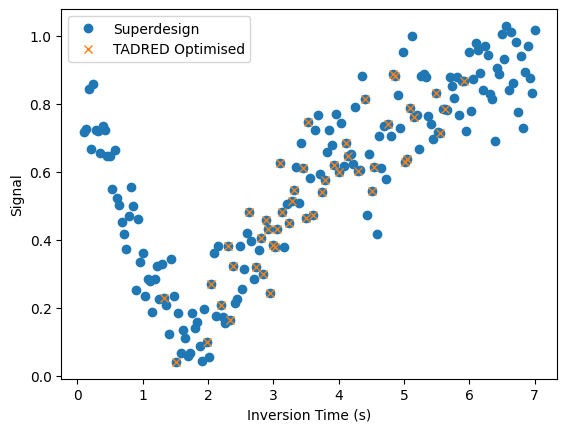

In [7]:
#load the optimised protocol and plot it
optimised_protocol = np.loadtxt(optimised_protocol_path)
optimised_indices = np.loadtxt(optimised_indices_path, dtype=int)

if MODEL == "SANDI":
    b_tadred = _calculate_b(optimised_protocol[:, 0] * 1e-3, optimised_protocol[:, 1] * 1e-3, optimised_protocol[:, 2] * 1e-3)

    Delta_super = super_protocol[:, 1] 
    Delta_tadred = optimised_protocol[:, 1]

    plt.plot(
            b_super,
            super_signals[0, :],
            "o"
        )

    plt.plot(
            b_tadred,
            super_signals[0, optimised_indices],
            "x"
        )

    plt.ylabel("Signal")
    plt.xlabel("b-value (s/mm²)")
    plt.legend(["Superdesign", "TADRED Optimised"])

else:
    plt.plot(
            super_protocol[0,:],
            super_signals[0, :],
            "o"
        )

    plt.plot(
            optimised_protocol,
            super_signals[0, optimised_indices],
            "x"
        )

    plt.ylabel("Signal")
    if MODEL == "T1INV":
        plt.xlabel("Inversion Time (s)")
    elif MODEL == "ADC":
        plt.xlabel("b-value")
    plt.legend(["Superdesign", "TADRED Optimised"])





plt.show()

In [8]:
#simulate some new data using the optimised protocol - fixed SNR

SNR = 20
n_test_samples = 10000


!{sys.executable} "{PROJECT_ROOT}/examples/generate_simulation_data.py" \
    "--model" {MODEL} \
    "--protocol" {optimised_protocol_path} \
    "--snr-min" {SNR} \
    "--snr-max" {SNR} \
    "--n-samples" {n_test_samples} \
#!{sys.executable} "{PROJECT_ROOT}/examples/generate_simulation_data.py"


tadred_signals_path = EXAMPLE_DATA_PATH / MODEL / "tadred_signals.npy"
tadred_targets_path = EXAMPLE_DATA_PATH / MODEL / "tadred_targets.npy"

tadred_signals = np.load(tadred_signals_path)
tadred_targets = np.load(tadred_targets_path)


Simulated MRI data generation complete.
Model:              T1INV
Number of voxels:   10000
Protocol length:    48
SNR range:          20.0 - 20.0
Signals dim:        (10000, 48)
Targets dim:        (10000, 1)
Protocol dim:       (48,)
Protocol file:      /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/results/optimisation/examples/T1INV/tadred_results/optimised_protocol.txt
Saved to:           /Users/paddyslator/python/ED_MRI_CLEAN/ED_MRI/examples/data/T1INV
  - tadred_signals.npy: simulated MRI signals
  - tadred_targets.npy: corresponding ground-truth model parameters



In [9]:
#Apply the task network to the data acquired with the optimised protocol

!edmri-apply \
    --example {MODEL} \
    --config "{CONFIG_PATH}/apply_default.yaml" \
    "data.input={tadred_signals_path}" \
    "task_network={task_network_path}" \
    --force
    




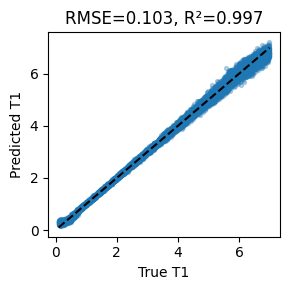

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from edmri import simulation

# Load predictions
predicted_parameters_path = EXAMPLE_APPLY_RESULTS_PATH / MODEL / "predictions.npy"
tadred_predicted_parameters = np.load(predicted_parameters_path)

# Get model parameter names
PARAM_NAMES = getattr(simulation, MODEL).PARAM_NAMES

# Create 1 x N subplots
n_params = tadred_targets.shape[1]
fig, axes = plt.subplots(1, n_params, figsize=(3 * n_params, 3))
axes = np.atleast_1d(axes)

for i, ax in enumerate(axes):
    truth = tadred_targets[:, i]
    pred = tadred_predicted_parameters[:, i]

    rmse = np.sqrt(np.mean((pred - truth) ** 2))
    r2 = 1 - np.sum((pred - truth) ** 2) / np.sum((truth - truth.mean()) ** 2)

    ax.scatter(truth, pred, s=8, alpha=0.3)
    ax.plot([truth.min(), truth.max()], [truth.min(), truth.max()], "k--")

    ax.set(
        xlabel=f"True {PARAM_NAMES[i]}",
        ylabel=f"Predicted {PARAM_NAMES[i]}",
        title=f"RMSE={rmse:.3g}, R²={r2:.3f}",
    )

plt.tight_layout()
plt.show()

In [11]:
#TO DO: now we'll train a new neural network on the full superdesign data to compare
!ls {EXAMPLE_APPLY_RESULTS_PATH / MODEL}




completed.flag  config.yaml     predictions.npy
